# Sentiment Analysis

**Task:** DA4  
**Data provenance:** Financial PhraseBank sentences_allagree, CC BY-NC-SA 3.0; financial-news sentiment.

This notebook calls a clearly separated, commented analysis module so the workflow can be run and maintained consistently. Run the cells from top to bottom. Metrics and plots are calculated at runtime; no results have been hand-entered. Synthetic-data outputs are demonstrations only.

## Notebook roadmap
This executed notebook separates data preparation, visualization, model training or analysis, and evaluation. Figures appear inline; each chart is followed by a written interpretation.

## Data Loading / EDA
Load the task dataset, verify its provenance and structure, and inspect its first descriptive summaries before visualization or model analysis.

In [1]:
from pathlib import Path
import sys
project = Path.cwd().resolve()
if not (project / 'analysis_tasks.py').is_file(): raise FileNotFoundError('Run Jupyter with this task folder as the working directory.')
sys.path.insert(0, str(project))
from analysis_tasks import *
from IPython.display import display
OUT_DIR.mkdir(exist_ok=True)
_chart_index = 0
_original_show = plt.show
def _save_inline_figure(*args, **kwargs):
    global _chart_index
    if plt.get_fignums():
        plt.gcf().savefig(OUT_DIR / f'notebook_chart_{_chart_index + 1:02d}.png', dpi=150, bbox_inches='tight')
        _chart_index += 1
    return _original_show(*args, **kwargs)
plt.show = _save_inline_figure


In [2]:
if not PHRASEBANK_PATH.exists():
    raise FileNotFoundError(f"Download Financial PhraseBank as described in README.md; expected {PHRASEBANK_PATH}.")

rows=[]

for line in PHRASEBANK_PATH.read_text(encoding="latin-1").splitlines():
    if "@" in line:
        text,label=line.rsplit("@",1)
        rows.append((label.strip().lower(),text.strip()))

df=pd.DataFrame(rows,columns=["sentiment","text"]).drop_duplicates()

print("DATA PROVENANCE: Financial PhraseBank Sentences_AllAgree; financial news, investor-perspective labels; CC BY-NC-SA 3.0.")

report(df)

print("Class distribution:\n",df["sentiment"].value_counts())

DATA PROVENANCE: Financial PhraseBank Sentences_AllAgree; financial news, investor-perspective labels; CC BY-NC-SA 3.0.
Shape: (2259, 2)

Dtypes:
 sentiment    str
text         str
dtype: object

Nulls:
 sentiment    0
text         0
dtype: int64

Descriptive statistics:
           count unique                                                top  \
sentiment  2259      3                                            neutral   
text       2259   2259  According to Gran , the company has no plans t...   

           freq  
sentiment  1386  
text          1  
Class distribution:
 sentiment
neutral     1386
positive     570
negative     303
Name: count, dtype: int64


## Visualizations
Each chart is rendered inline and saved under `outputs/`; its interpretation follows immediately.

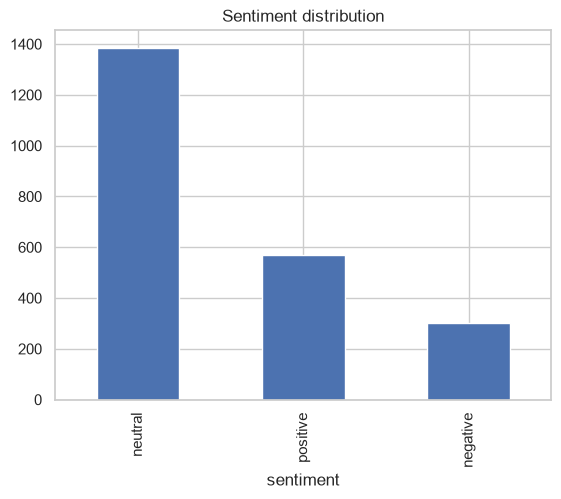

In [3]:
df.sentiment.value_counts().plot.bar(title="Sentiment distribution")
plt.show()

### Chart 1 interpretation
Class counts reveal corpus label balance; macro-F1 and per-class recall matter when classes differ in prevalence.

## Model Training / Analysis
Fit and assess the task model, or perform the task-specific analysis when predictive training does not apply.


Multinomial NB: accuracy=0.783, macro-F1=0.555
              precision    recall  f1-score   support

    negative       1.00      0.05      0.09        61
     neutral       0.85      0.97      0.91       277
    positive       0.62      0.71      0.66       114

    accuracy                           0.78       452
   macro avg       0.82      0.58      0.55       452
weighted avg       0.81      0.78      0.74       452

Confusion matrix:
 [[  3  16  42]
 [  0 270   7]
 [  0  33  81]]



Logistic regression: accuracy=0.825, macro-F1=0.736
              precision    recall  f1-score   support

    negative       0.87      0.44      0.59        61
     neutral       0.86      0.95      0.91       277
    positive       0.71      0.72      0.72       114

    accuracy                           0.83       452
   macro avg       0.82      0.70      0.74       452
weighted avg       0.83      0.83      0.81       452

Confusion matrix:
 [[ 27  11  23]
 [  3 264  10]
 [  1  31  82]]
Best model by held-out macro-F1: Logistic regression (macro-F1=0.736).
Misclassified examples with review notes:
                                                                                                                                                text   actual predicted                                                       review_note
                                                    In September alone , the market declined by 10.2 percent year-on-year to 19.28 million liters . negati

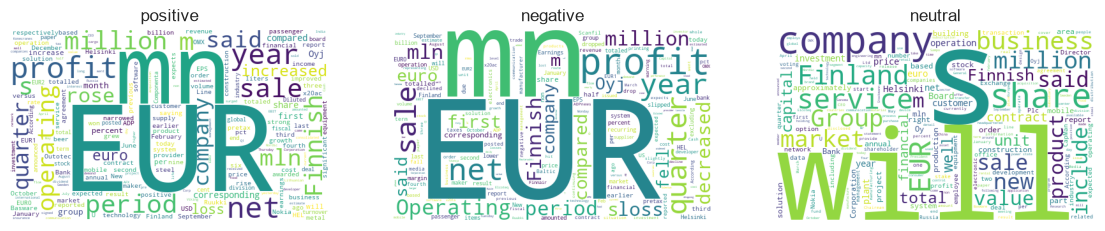

In [4]:
x_train,x_test,y_train,y_test=train_test_split(df.text,df.sentiment,test_size=.2,random_state=SEED,stratify=df.sentiment)

vectorizer=TfidfVectorizer(lowercase=True,stop_words="english",strip_accents="unicode",
                           token_pattern=r"(?u)\b\w\w+\b",ngram_range=(1,2))

a,b=vectorizer.fit_transform(x_train),vectorizer.transform(x_test)

results=[score_classifier("Multinomial NB",MultinomialNB(),a,b,y_train,y_test),
         score_classifier("Logistic regression",LogisticRegression(max_iter=500),a,b,y_train,y_test)]

best=max(results,key=lambda r:r["f1"])

print(f"Best model by held-out macro-F1: {best['name']} (macro-F1={best['f1']:.3f}).")

mistakes=pd.DataFrame({"text":x_test,"actual":y_test,"predicted":best["prediction"]})

mistakes=mistakes[mistakes.actual!=mistakes.predicted].head(5).copy()

if mistakes.empty:
    print("Error analysis: no misclassifications in this held-out sample.")
else:
    mistakes["review_note"]=mistakes["text"].apply(
        lambda text: "Check negation or contrast; word-level features can miss context."
        if re.search(r"\b(not|no|never|despite|although|but)\b",text.lower())
        else "Check implicit financial context and subjective label boundaries."
    )
    print("Misclassified examples with review notes:\n",mistakes.to_string(index=False))

try:
    from wordcloud import WordCloud
    fig,axes=plt.subplots(1,3,figsize=(14,4))
    for axis,label in zip(axes,("positive","negative","neutral")):
        corpus=" ".join(df.loc[df.sentiment==label,"text"])
        axis.imshow(WordCloud(width=500,height=300,background_color="white",collocations=False).generate(corpus))
        axis.set_title(label); axis.axis("off")
    plt.show()
except ImportError:
    print("Optional wordcloud package unavailable; top-word plots are used instead.")
    for label in df.sentiment.unique():
        words=" ".join(df.loc[df.sentiment==label,"text"]).lower()
        pd.Series(re.findall(r"[a-z]+",words)).value_counts().head(10).sort_values().plot.barh(title=f"Top words: {label}")
        plt.show()

### Chart 2 interpretation
Class-specific terms can help explain predictions, but word clouds omit context such as negation and contrast.

In [5]:
print("TF-IDF weights terms by local frequency and corpus-wide rarity. This model can support triage of financial news, but the finance-domain labels may not generalize to product reviews or social media.")

TF-IDF weights terms by local frequency and corpus-wide rarity. This model can support triage of financial news, but the finance-domain labels may not generalize to product reviews or social media.


## Evaluation
Review the held-out metrics or descriptive summary below. Predictive scores apply only to this dataset and split.

In [6]:
evaluation_rows = []
for variable in ('results', 'models', 'result'):
    candidate = globals().get(variable)
    for row in candidate if isinstance(candidate, list) else [candidate]:
        if isinstance(row, dict):
            metrics = {k:v for k,v in row.items() if isinstance(v,(int,float,np.number)) and not isinstance(v,(bool,np.bool_))}
            if metrics: evaluation_rows.append({'model':row.get('name',variable),**metrics})
if not evaluation_rows and {'y_test','pred'}.issubset(globals()):
    from sklearn.metrics import precision_score,recall_score,f1_score
    evaluation_rows.append({'model':'Fraud holdout at threshold 0.50','precision':precision_score(y_test,pred,zero_division=0),'recall':recall_score(y_test,pred,zero_division=0),'f1':f1_score(y_test,pred,zero_division=0)})
if evaluation_rows: evaluation=pd.DataFrame(evaluation_rows)
elif isinstance(globals().get('summary'),pd.DataFrame): evaluation=summary.copy()
elif isinstance(globals().get('profile'),pd.DataFrame): evaluation=profile.copy()
elif isinstance(globals().get('monthly'),pd.Series): evaluation=monthly.rename('revenue').to_frame()
else: evaluation=pd.DataFrame([{'analysis':'Financial PhraseBank Sentiment Analysis','rows':len(df) if isinstance(globals().get('df'),pd.DataFrame) else None,'columns':len(df.columns) if isinstance(globals().get('df'),pd.DataFrame) else None,'charts':_chart_index}])
display(evaluation)
evaluation_path=OUT_DIR/'evaluation_summary.csv'
evaluation.to_csv(evaluation_path,index=True)
print(f'Saved {_chart_index} chart(s) and evaluation summary: {evaluation_path}')

,model,accuracy,f1
0,Multinomial NB,0.783186,0.554575
1,Logistic regression,0.825221,0.736258


Saved 2 chart(s) and evaluation summary: D:\Oasis\DataAnalytics-L1-SentimentAnalysis\outputs\evaluation_summary.csv
